In [2]:
import xarray as xr

In [7]:
xr.open_zarr("inputs/WHACS/processed/WHACS_netherlands.zarr").load()[
    ["seapoint", "longitude", "latitude", "goal"]
].to_dataframe().reset_index().to_csv("inputs/WHACS/WHACS_coordinates.csv",index=False)

In [4]:
xr.open_zarr("inputs/WHACS/processed/WHACS_netherlands.zarr").load()

<xarray.Dataset> Size: 1GB
Dimensions:                      (time: 394464, goal: 10)
Coordinates:
  * time                         (time) datetime64[ns] 3MB 1979-01-01 ... 202...
  * goal                         (goal) int64 80B 1 2 3 4 5 6 7 8 9 10
    latitude                     (goal) float64 80B 54.0 54.0 54.0 ... 52.0 51.5
    longitude                    (goal) float64 80B 7.0 6.5 6.0 ... 3.5 3.0 2.5
    seapoint                     (goal) int64 80B 2326142 2326133 ... 2323617
Data variables: (12/39)
    cge                          (time, goal) float64 32MB 53.0 46.5 ... 29.4
    dir                          (time, goal) float64 32MB 51.7 58.6 ... 236.1
    dp                           (time, goal) float64 32MB 55.0 64.0 ... 236.0
    fp                           (time, goal) float64 32MB 0.112 0.112 ... 0.142
    hs                           (time, goal) float64 32MB 3.686 3.416 ... 2.978
    pdir0                        (time, goal) float64 32MB 51.7 58.6 ... 236.0
    ...                           ...
    ptp3                         (time, goal) float64 32MB nan nan ... nan nan
    spr                          (time, goal) float64 32MB 27.5 27.7 ... 21.8
    t01                          (time, goal) float64 32MB 6.89 6.7 ... 5.84
    t02                          (time, goal) float64 32MB 6.29 6.1 ... 5.42
    uwnd                         (time, goal) float64 32MB -9.5 -9.1 ... 12.6
    vwnd                         (time, goal) float64 32MB -9.4 -9.0 ... 7.8 8.7
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

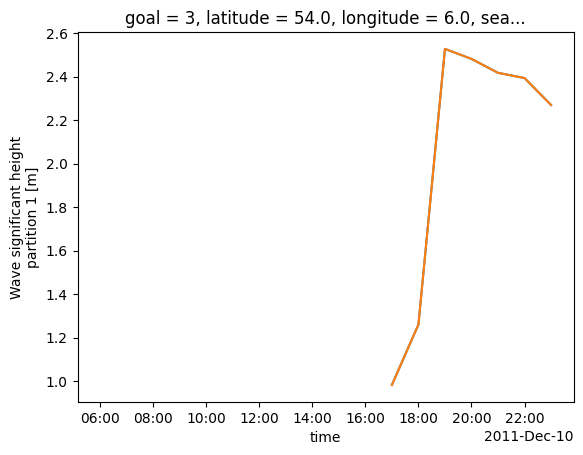

In [5]:
import xarray as xr

xr.open_dataset(
    "https://geoocean.unican.es/thredds/dodsC/rawData/CSIRO/WHACS/global-smc/phs1/phs1_WHACS_hindcast_WHACS_ERA5_1hr_201112010000-201112312300.nc"
).sel(seapoint=2326127, time="2011-12-10").phs1.plot()
xr.open_zarr("inputs/WHACS/processed/WHACS_netherlands.zarr").sel(
    goal=3, time="2011-12-10"
).phs1.plot()

In [ ]:
wacs = (
    xr.open_zarr("inputs/WHACS/processed/OLD_WHACS_netherlands.zarr")
    .rename({"seapoint": "goal"})
    .drop(["latitude", "longitude"])
)
wacs["goal"] = list(range(1, 11))[::-1]
wacs = (
    wacs.assign_coords(
        {
            "seapoint": (
                ("goal"),
                [
                    2323617,
                    2334975,
                    2324234,
                    2324697,
                    2325243,
                    2326117,
                    2326121,
                    2326127,
                    2326133,
                    2326142,
                ],
            ),
            "longitude": (
                ("goal"),
                [
                    2.5,
                    3.0,
                    3.5,
                    4.0,
                    4.5,
                    5.0,
                    5.5,
                    6.0,
                    6.5,
                    7.0,
                ],
            ),
            "latitude": (
                ("goal"),
                [
                    51.5,
                    52.0,
                    52.5,
                    53.0,
                    53.5,
                    54.0,
                    54.0,
                    54.0,
                    54.0,
                    54.0,
                ],
            ),
        }
    )
    .sortby("goal")
    .load()
)
wacs

/tmp/ipykernel_1548695/1168436060.py:4: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop(["latitude", "longitude"])


<xarray.Dataset> Size: 1GB
Dimensions:                      (time: 394464, goal: 10)
Coordinates:
  * time                         (time) datetime64[ns] 3MB 1979-01-01 ... 202...
  * goal                         (goal) int64 80B 1 2 3 4 5 6 7 8 9 10
    seapoint                     (goal) int64 80B 2326142 2326133 ... 2323617
    longitude                    (goal) float64 80B 7.0 6.5 6.0 ... 3.5 3.0 2.5
    latitude                     (goal) float64 80B 54.0 54.0 54.0 ... 52.0 51.5
Data variables: (12/39)
    cge                          (time, goal) float64 32MB 53.0 46.5 ... 29.4
    dir                          (time, goal) float64 32MB 51.7 58.6 ... 236.1
    dp                           (time, goal) float64 32MB 55.0 64.0 ... 236.0
    fp                           (time, goal) float64 32MB 0.112 0.112 ... 0.142
    hs                           (time, goal) float64 32MB 3.686 3.416 ... 2.978
    pdir0                        (time, goal) float64 32MB 51.7 58.6 ... 236.0
    ...                           ...
    ptp3                         (time, goal) float64 32MB nan nan ... nan nan
    spr                          (time, goal) float64 32MB 27.5 27.7 ... 21.8
    t01                          (time, goal) float64 32MB 6.89 6.7 ... 5.84
    t02                          (time, goal) float64 32MB 6.29 6.1 ... 5.42
    uwnd                         (time, goal) float64 32MB -9.5 -9.1 ... 12.6
    vwnd                         (time, goal) float64 32MB -9.4 -9.0 ... 7.8 8.7
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [24]:
wacs.to_zarr("inputs/WHACS/processed/WHACS_netherlands.zarr")

/home/tausiaj/miniforge3/envs/bluemath-311-dev/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


In [10]:
codec.to_zarr("inputs/CODEC/processed/CODEC_netherlands.zarr")

/home/tausiaj/miniforge3/envs/bluemath-311-dev/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


In [1]:
import xarray as xr

for station in [23778, 23711, 23651, 23599, 23541, 23462, 23369, 23269, 23190, 23125]:
    codec = (
        xr.open_dataset(
            "https://geoocean.unican.es/thredds/dodsC/aggregatedDatasets/CODEC.nc"
        )
        .sel(stations=station)
        .chunk({"time": 365 * 24})
        .load()
    )
    codec.to_netcdf(f"inputs/CODEC/CODEC_{station}.nc")

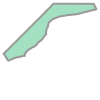

In [1]:
import alphashape
import numpy as np
import xarray as xr

mesh_nc = xr.open_dataset("inputs/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.nc")
ocean_region = alphashape.alphashape(
    np.column_stack([mesh_nc.mesh2d_node_x.values, mesh_nc.mesh2d_node_y.values])[
        ::5, :
    ],
    10,
)
ocean_region

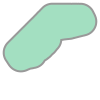

In [6]:
ocean_region = ocean_region.buffer(1)
ocean_region

In [11]:
import xarray as xr

codec_stations = xr.open_dataset(
    "https://geoocean.unican.es/thredds/dodsC/aggregatedDatasets/CODEC.nc"
)[["station_x_coordinate", "station_y_coordinate"]].load()
codec_stations

<xarray.Dataset> Size: 776kB
Dimensions:               (stations: 43119)
Coordinates:
  * stations              (stations) int16 86kB 0 1 2 3 ... -21805 -21804 -21803
    station_x_coordinate  (stations) float64 345kB 24.09 24.09 ... 37.75 37.95
    station_y_coordinate  (stations) float64 345kB 34.83 34.87 ... -46.98 -46.63
Data variables:
    *empty*
Attributes: (12/35)
    Conventions:                   CF-1.6
    featureType:                   timeSeries
    id:                            GTSMv3_surge
    naming_authority:              https://deltares.nl/en
    Metadata_Conventions:          Unidata Dataset Discovery v1.0
    title:                         CODEC
    ...                            ...
    time_coverage_start:           2018-11-01 00:00:00
    time_coverage_end:             2018-11-30 23:00:00
    experiment:                    reanalysis
    date_modified:                 2021-05-06 19:47:58.279267 UTC
    contact:                       Please contact Copernicus User Support on ...
    history:                       Created on 2024-12-08

In [7]:
from shapely.geometry import Point

interest_locations = []

for i, (codec_station_x, codec_station_y) in enumerate(
    zip(
        codec_stations.station_x_coordinate.values,
        codec_stations.station_y_coordinate.values,
    )
):
    if Point(codec_station_x, codec_station_y).within(ocean_region):
        interest_locations.append(i)

In [8]:
len(interest_locations)

407

In [ ]:
# codec_stations = codec_stations.isel(stations=interest_locations)
# codec_stations

In [12]:
codec_stations = codec_stations.sel(
    stations=[23778, 23711, 23651, 23599, 23541, 23462, 23369, 23269, 23190, 23125]
)
codec_stations

<xarray.Dataset> Size: 180B
Dimensions:               (stations: 10)
Coordinates:
  * stations              (stations) int16 20B 23778 23711 23651 ... 23190 23125
    station_x_coordinate  (stations) float64 80B 6.987 6.489 ... 3.003 2.498
    station_y_coordinate  (stations) float64 80B 54.01 54.01 ... 51.99 51.49
Data variables:
    *empty*
Attributes: (12/35)
    Conventions:                   CF-1.6
    featureType:                   timeSeries
    id:                            GTSMv3_surge
    naming_authority:              https://deltares.nl/en
    Metadata_Conventions:          Unidata Dataset Discovery v1.0
    title:                         CODEC
    ...                            ...
    time_coverage_start:           2018-11-01 00:00:00
    time_coverage_end:             2018-11-30 23:00:00
    experiment:                    reanalysis
    date_modified:                 2021-05-06 19:47:58.279267 UTC
    contact:                       Please contact Copernicus User Support on ...
    history:                       Created on 2024-12-08

In [ ]:
# check consistency with
# https://geoocean.unican.es/thredds/dodsC/rawData/Copernicus/CODEC/twl/
# reanalysis_waterlevel_hourly_1997_09_v1.nc.html

In [13]:
# Write station_x and y into txt file
with open("codec_stations.txt", "w") as f:
    for station_id, codec_station_x, codec_station_y in zip(
        codec_stations.stations.values,
        codec_stations.station_x_coordinate.values,
        codec_stations.station_y_coordinate.values,
    ):
        f.write(f"{station_id} {codec_station_x} {codec_station_y}\n")

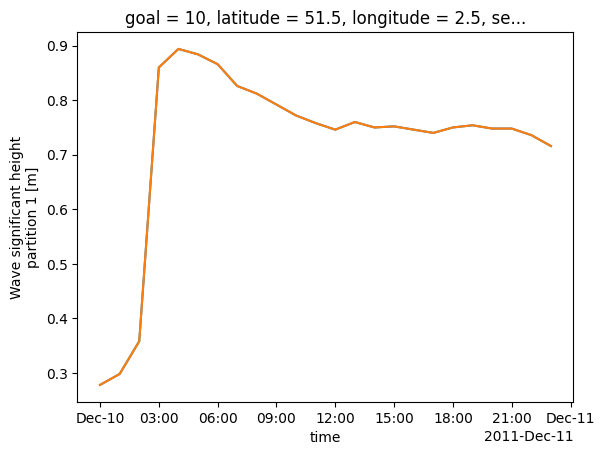

In [13]:
import xarray as xr

xr.open_dataset(
    "https://geoocean.unican.es/thredds/dodsC/rawData/CSIRO/WHACS/global-smc/phs1/phs1_WHACS_hindcast_WHACS_ERA5_1hr_201112010000-201112312300.nc"
).sel(seapoint=2323617, time="2011-12-10").phs1.plot()
xr.open_zarr("inputs/WHACS/processed/WHACS_netherlands.zarr").sel(
    goal=10, time="2011-12-10"
).phs1.plot()

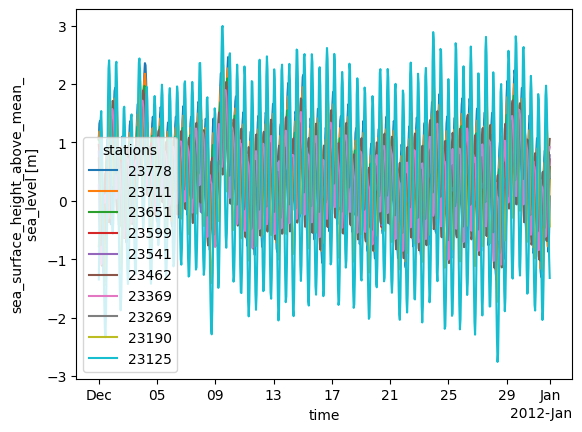

In [2]:
codec.waterlevel.plot(hue="stations")